In [23]:
import pandas as pd
import numpy as np

In [24]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.expand_frame_repr', False)

In [25]:
dt = pd.read_csv(r"D:\Download\2019.csv")

duplicate_count = dt.duplicated().sum()
dt = dt.drop_duplicates()
print("Số dòng đã xóa:", duplicate_count)
print(dt)

Số dòng đã xóa: 0
     Overall rank         Country or region  Score  GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
0               1                   Finland  7.769           1.340           1.587                    0.986                         0.596       0.153                      0.393
1               2                   Denmark  7.600           1.383           1.573                    0.996                         0.592       0.252                      0.410
2               3                    Norway  7.554           1.488           1.582                    1.028                         0.603       0.271                      0.341
3               4                   Iceland  7.494           1.380           1.624                    1.026                         0.591       0.354                      0.118
4               5               Netherlands  7.488           1.396           1.522               

In [26]:
#1) Xóa cột định danh, gây data leakage
X = dt.drop(columns=['Overall rank', 'Country or region', 'Score'])
print(X)

     GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
0             1.340           1.587                    0.986                         0.596       0.153                      0.393
1             1.383           1.573                    0.996                         0.592       0.252                      0.410
2             1.488           1.582                    1.028                         0.603       0.271                      0.341
3             1.380           1.624                    1.026                         0.591       0.354                      0.118
4             1.396           1.522                    0.999                         0.557       0.322                      0.298
..              ...             ...                      ...                           ...         ...                        ...
151           0.359           0.711                    0.614                         0.555

In [27]:
from scipy.stats import zscore
import matplotlib.pyplot as plt

In [28]:
zScore = X.apply(zscore)

print(zScore.head())
print("\nĐộ lệch chuẩn (std):\n", zScore.std())
print("\nTrung bình (mean):\n", zScore.mean())
print("\nGiá trị nhỏ nhất (min):\n", zScore.min())
print("\nGiá trị lớn nhất (max):\n", zScore.max())

print("\nTỷ lệ dữ liệu trong khoảng [-3, 3]:")
print(np.mean(np.abs(zScore) < 3, axis=0))  

   GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
0        1.095042        1.268098                 1.080422                      1.424282   -0.335404                   2.996757
1        1.203324        1.221154                 1.121857                      1.396277    0.707265                   3.177158
2        1.467734        1.251332                 1.254446                      1.473292    0.907373                   2.444941
3        1.195769        1.392163                 1.246159                      1.389276    1.781530                   0.078500
4        1.236060        1.050146                 1.134287                      1.151229    1.444506                   1.988632

Độ lệch chuẩn (std):
 GDP per capita                  1.003221
Social support                  1.003221
Healthy life expectancy         1.003221
Freedom to make life choices    1.003221
Generosity                      1.003221
Perc

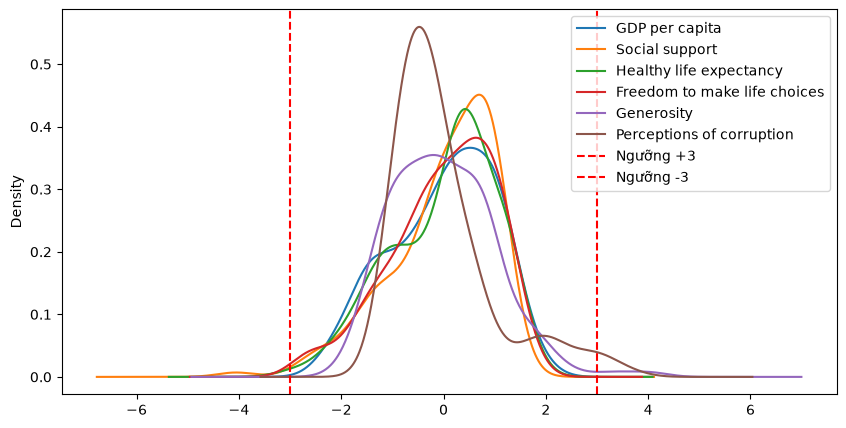

In [29]:
zScore.plot.kde(figsize=(10, 5))
plt.axvline(3, linestyle='--', color='red', label='Ngưỡng +3')
plt.axvline(-3, linestyle='--', color='red', label='Ngưỡng -3')
plt.legend()
plt.show()

In [30]:
# zScore = zScore.clip(-3, 3)

# print("Tỷ lệ sau khi xử lý outlier:")
# print(np.mean(np.abs(zScore) <= 3, axis=0))

In [31]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

In [32]:
class K_Distance:
    def __init__(self, k=4):
        self.k = k
        self.distances = None
        self.indices = None
        self.k_distances = None

    def __distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def __k_neighbors(self, X, row_idx):
        dists = np.zeros(X.shape[0])
        for j in range(X.shape[0]):
            dists[j] = self.__distance(X[row_idx], X[j])
        
        sorted_idx = np.argsort(dists)
        return dists[sorted_idx[:self.k]], sorted_idx[:self.k]

    def fit(self, X):
        n_samples = X.shape[0]
        self.distances = np.zeros((n_samples, self.k))
        self.indices = np.zeros((n_samples, self.k), dtype=int)

        for i in range(n_samples):
            self.distances[i], self.indices[i] = self.__k_neighbors(X, i)

        self.k_distances = np.sort(self.distances[:, self.k - 1])

    def plot(self, eps_suggest=1.15):
        plt.figure(figsize=(8, 4))
        plt.plot(self.k_distances, linewidth=2)
        plt.axhline(y=eps_suggest, color='red', linestyle='--', label=f'Vùng khuỷu tay (eps ≈ {eps_suggest})')
        plt.title(f'Biểu đồ K-distance (k = {self.k}) tìm tham số eps')
        plt.xlabel('Các quốc gia (đã sắp xếp)')
        plt.ylabel(f'Khoảng cách tới hàng xóm thứ {self.k} (eps)')
        plt.legend()
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.show()

10 khoảng cách nhỏ nhất: [0.4905 0.5045 0.5097 0.5716 0.575  0.575  0.5787 0.6128 0.6178 0.6427]
10 khoảng cách lớn nhất: [1.8944 1.9423 2.0132 2.0685 2.0956 2.2779 2.4143 2.5593 2.6275 3.0675]


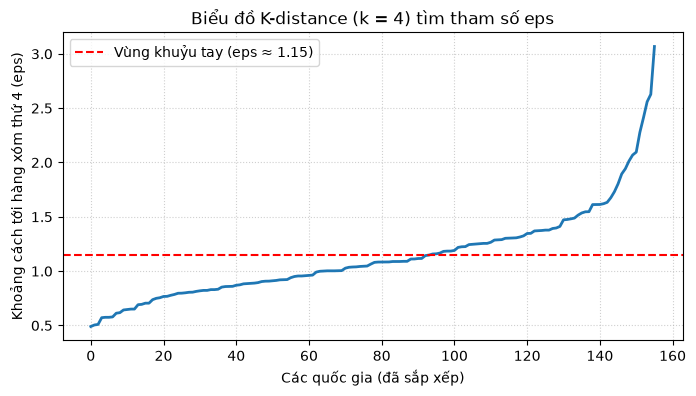

In [33]:
model = K_Distance(k=4)
model.fit(zScore.values)

print("10 khoảng cách nhỏ nhất:", np.round(model.k_distances[:10], 4))
print("10 khoảng cách lớn nhất:", np.round(model.k_distances[-10:], 4))
model.plot(eps_suggest=1.15) 